In [ ]:
# ============================================================
# NOTEBOOK PHÂN TÍCH TÁI LẬP – CNN LÁ NGÔ (FAIR)
# Mục tiêu: Tái lập đầy đủ từ dữ liệu thô → thống kê → huấn luyện
#           → kiểm định thống kê → Grad-CAM
# Mọi random đã cố định seed.
# ============================================================

In [ ]:
# ---------- KHỞI TẠO DANH SÁCH DỮ LIỆU & KIỂM TRA CHẤT LƯỢNG ẢNH ----------
import hashlib
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

# 1. Định nghĩa đường dẫn và danh sách ảnh (samples)
OUT_DIR = Path("/kaggle/working")
DATA_DIR = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")
CLASSES = [
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
]
SHORT = ["Cercospora", "Common rust", "Northern Leaf Blight", "healthy"]
K = len(CLASSES)

samples = []
for idx, cls_name in enumerate(CLASSES):
    for p in sorted((DATA_DIR / cls_name).iterdir()):
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}:
            samples.append((p, idx))
N = len(samples)

# 2. Kiểm tra chất lượng ảnh (Hash trùng, ảnh hỏng, độ sáng, độ sắc nét)
quality_records = []
seen_hashes = {}
duplicate_count = 0
corrupted_count = 0

for img_path, label in samples:
    path_str = str(img_path)
    try:
        # Kiểm tra ảnh hỏng bằng cách mở và verify
        with Image.open(path_str) as img:
            img.verify()

        # Tính MD5 hash để phát hiện ảnh trùng lặp tuyệt đối
        with open(path_str, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        
        if file_hash in seen_hashes:
            duplicate_count += 1
        else:
            seen_hashes[file_hash] = path_str

        # Tính độ sáng (Brightness) và độ sắc nét (Laplacian Variance)
        img_bgr = cv2.imread(path_str)
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        
        brightness = float(np.mean(gray))
        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        
        quality_records.append({
            "class": SHORT[label],
            "brightness": brightness,
            "sharpness": sharpness
        })
    except Exception as e:
        corrupted_count += 1
        print(f"Ảnh lỗi: {path_str} ({e})")

df_quality = pd.DataFrame(quality_records)

print("=== BÁO CÁO CHẤT LƯỢNG DỮ LIỆU ẢNH ===")
print(f"- Tổng số ảnh kiểm tra : {N}")
print(f"- Số ảnh bị hỏng/lỗi   : {corrupted_count}")
print(f"- Số ảnh trùng MD5 hash: {duplicate_count}")
print("\n--- Thống kê Độ sáng (Brightness) & Độ sắc nét (Laplacian Variance) theo lớp ---")
summary_q = df_quality.groupby("class")[["brightness", "sharpness"]].agg(["mean", "std", "min", "max"])
print(summary_q.round(2))

# Lưu báo cáo chất lượng ảnh ra CSV
summary_q.to_csv(OUT_DIR / "image_quality_summary.csv")
print("\nĐã lưu báo cáo chất lượng ảnh: image_quality_summary.csv")

In [ ]:
# ---------- KIỂM TRA CHẤT LƯỢNG ẢNH (HASH TRÙNG, ẢNH HỎNG, ĐỘ SÁNG, ĐỘ SẮC NÉT) ----------
import hashlib
import cv2
import numpy as np
import pandas as pd
from PIL import Image

quality_records = []
seen_hashes = {}
duplicate_count = 0
corrupted_count = 0

for img_path, label in samples:
    path_str = str(img_path)
    try:
        # 1. Kiểm tra ảnh hỏng bằng cách mở và verify
        with Image.open(path_str) as img:
            img.verify()

        # 2. Tính MD5 hash để phát hiện ảnh trùng lặp tuyệt đối
        with open(path_str, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        
        if file_hash in seen_hashes:
            duplicate_count += 1
        else:
            seen_hashes[file_hash] = path_str

        # 3. Tính độ sáng (Brightness) và độ sắc nét (Laplacian Variance)
        img_bgr = cv2.imread(path_str)
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        
        brightness = float(np.mean(gray))
        sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        
        quality_records.append({
            "class": SHORT[label],
            "brightness": brightness,
            "sharpness": sharpness
        })
    except Exception as e:
        corrupted_count += 1
        print(f"Ảnh lỗi: {path_str} ({e})")

df_quality = pd.DataFrame(quality_records)

print("=== BÁO CÁO CHẤT LƯỢNG DỮ LIỆU ẢNH ===")
print(f"- Tổng số ảnh kiểm tra : {len(samples)}")
print(f"- Số ảnh bị hỏng/lỗi   : {corrupted_count}")
print(f"- Số ảnh trùng MD5 hash: {duplicate_count}")
print("\n--- Thống kê Độ sáng (Brightness) & Độ sắc nét (Laplacian Variance) theo lớp ---")
summary_q = df_quality.groupby("class")[["brightness", "sharpness"]].agg(["mean", "std", "min", "max"])
print(summary_q.round(2))

# Lưu báo cáo chất lượng ảnh ra CSV
summary_q.to_csv(OUT_DIR / "image_quality_summary.csv")
print("\nĐã lưu báo cáo chất lượng ảnh: image_quality_summary.csv")

In [ ]:
# ---------- THỐNG KÊ MÔ TẢ ----------
from collections import Counter
import matplotlib.pyplot as plt

# Đếm số ảnh từng lớp
label_counts = Counter([lab for _, lab in samples])
print("Phân bố số ảnh theo lớp:")
for i, name in enumerate(SHORT):
    print(f"  {name:25s}: {label_counts[i]:4d} ảnh ({label_counts[i]/N*100:.1f}%)")

# Biểu đồ
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(SHORT, [label_counts[i] for i in range(K)], color=["#e74c3c", "#3498db", "#2ecc71", "#9b59b6"])
ax.set_ylabel("Số ảnh")
ax.set_title("Phân bố lớp trong bộ PlantVillage Maize (n = 3852)")
for bar, c in zip(bars, [label_counts[i] for i in range(K)]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, str(c), ha="center")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(OUT_DIR / "class_distribution.png", dpi=150)
plt.show()
print("→ Nhận xét: Lớp Cercospora (Gray Leaf Spot) chỉ chiếm ~13.3% → mất cân bằng rõ rệt.")

In [1]:

import torch
from torch.utils.data import Dataset, Subset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from pathlib import Path
from PIL import Image
from collections import Counter

# Image and training settings
IMAGE_SIZE = 256
BATCH_SIZE = 32
SEED = 42

# Dataset location in Kaggle
DATA_DIR = Path(
    "/kaggle/input/datasets/abdallahalidev/"
    "plantvillage-dataset/color"
)

# Check whether a GPU is available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)
print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Dataset path exists:", DATA_DIR.exists())


PyTorch version: 2.11.0+cpu
Device: cpu
Image size: 256 x 256
Batch size: 32
Dataset path exists: True


In [4]:
import copy
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import binomtest, ttest_rel
from sklearn.model_selection import train_test_split

# ---------- 1. CẤU HÌNH ----------
SEEDS = [42, 43, 44, 45, 46]      # 5 lần huấn luyện độc lập
EPOCHS = 20                      # BẰNG NHAU cho cả hai mô hình (giảm xuống 10 nếu cần chạy nhanh)
BATCH_SIZE = 32
LR = 1e-3
IMAGE_SIZE = 256
SPLIT_SEED = 42                   # giữ nguyên để trùng cách chia ở các ô trước
N_BOOT = 2000                    # số lần lấy mẫu bootstrap
OUT_DIR = Path("/kaggle/working")
DATA_DIR = Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color")

CLASSES = [
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
]
SHORT = ["Cercospora", "Common rust", "Northern Leaf Blight", "healthy"]
K = len(CLASSES)
MODELS = {"CNN nền": False, "CNN + BN": True}   # tên -> có dùng BatchNorm không
SLUG = {"CNN nền": "base", "CNN + BN": "bn"}


# ---------- 2. HÀM ĐO LƯỜNG (numpy, chạy nhanh để bootstrap) ----------
def conf_mat(y, p):
    return np.bincount(y * K + p, minlength=K * K).reshape(K, K)


def f1_per_class(cm):
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    return np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)


def recall_per_class(cm):
    tp = np.diag(cm).astype(float)
    den = cm.sum(1)
    return np.where(den > 0, tp / np.maximum(den, 1), 0.0)


def macro_f1(y, p):
    return f1_per_class(conf_mat(y, p)).mean()


# ---------- 3. PHÂN TÍCH THỐNG KÊ ----------
def analyze(preds, y_test, names=("CNN nền", "CNN + BN"), seeds=SEEDS, n_boot=N_BOOT):
    """preds[tên_mô_hình][seed] = mảng dự đoán trên tập test."""
    a, b = names
    n = len(y_test)

    # (a) Kết quả từng lần chạy
    rows = []
    for name in names:
        for s in seeds:
            cm = conf_mat(y_test, preds[name][s])
            f1c = f1_per_class(cm)
            rows.append({
                "model": name, "seed": s,
                "test_accuracy": np.diag(cm).sum() / n,
                "macro_f1": f1c.mean(),
                "f1_cercospora": f1c[0],
                "recall_cercospora": recall_per_class(cm)[0],
            })
    df = pd.DataFrame(rows)

    # (b) Bootstrap: lấy mẫu lại ảnh test (cùng chỉ số cho cả hai mô hình -> ghép cặp)
    rng = np.random.default_rng(2026)
    boot_idx = rng.integers(0, n, size=(n_boot, n))
    boot = {name: np.zeros((len(seeds), n_boot)) for name in names}
    for name in names:
        for si, s in enumerate(seeds):
            p = preds[name][s]
            for bi in range(n_boot):
                ix = boot_idx[bi]
                boot[name][si, bi] = macro_f1(y_test[ix], p[ix])

    avg_boot = {name: boot[name].mean(axis=0) for name in names}   # trung bình qua các seed
    diff_boot = avg_boot[b] - avg_boot[a]
    ci = {name: np.percentile(avg_boot[name], [2.5, 97.5]) for name in names}
    diff_ci = np.percentile(diff_boot, [2.5, 97.5])

    # (c) Trung bình ± SD qua các seed (phản ánh dao động do huấn luyện)
    f1_a = df[df.model == a].sort_values("seed").macro_f1.values
    f1_b = df[df.model == b].sort_values("seed").macro_f1.values
    diff_seed = f1_b - f1_a
    t_res = ttest_rel(f1_b, f1_a)
    d_z = diff_seed.mean() / diff_seed.std(ddof=1) if diff_seed.std(ddof=1) > 0 else float("nan")

    # (d) McNemar chính xác cho từng seed (so sánh đúng/sai trên cùng ảnh test)
    mc = []
    for s in seeds:
        ok_a = preds[a][s] == y_test
        ok_b = preds[b][s] == y_test
        n01 = int((~ok_a & ok_b).sum())    # nền sai, BN đúng
        n10 = int((ok_a & ~ok_b).sum())    # nền đúng, BN sai
        p_val = binomtest(n01, n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
        mc.append({"seed": s, "nen_sai_BN_dung": n01, "nen_dung_BN_sai": n10, "p_value": p_val})
    mc = pd.DataFrame(mc)

    # (e) In báo cáo
    pd.set_option("display.width", 200)
    print("=" * 70)
    print("KẾT QUẢ TRÊN TẬP TEST (mỗi mô hình chạm test đúng 1 lần mỗi seed)")
    print("=" * 70)
    print(df.round(4).to_string(index=False))

    print("\n--- Trung bình ± SD qua", len(seeds), "seed ---")
    for name, arr in ((a, f1_a), (b, f1_b)):
        sub = df[df.model == name]
        print(f"{name:10s} | acc {sub.test_accuracy.mean():.4f} ± {sub.test_accuracy.std(ddof=1):.4f}"
              f" | macro-F1 {arr.mean():.4f} ± {arr.std(ddof=1):.4f}"
              f" | CI95% bootstrap [{ci[name][0]:.4f}; {ci[name][1]:.4f}]"
              f" | F1 Cercospora {sub.f1_cercospora.mean():.4f}"
              f" | recall Cercospora {sub.recall_cercospora.mean():.4f}")

    print(f"\n--- Chênh lệch macro-F1 ({b} − {a}) ---")
    print(f"Trung bình qua seed: {diff_seed.mean():+.4f}")
    print(f"CI95% bootstrap (lấy mẫu lại ảnh test): [{diff_ci[0]:+.4f}; {diff_ci[1]:+.4f}]")
    print(f"Kiểm định t ghép cặp qua seed: t = {t_res.statistic:.3f}, p = {t_res.pvalue:.4f}, d_z = {d_z:.2f}"
          f"  (chỉ {len(seeds)} seed: diễn giải thận trọng)")

    print("\n--- McNemar chính xác theo từng seed (dựa trên đúng/sai) ---")
    print(mc.round(4).to_string(index=False))
    print(f"Số seed có p < 0.05: {(mc.p_value < 0.05).sum()}/{len(seeds)}")

    if diff_ci[0] > 0:
        verdict = f"CI95% của chênh lệch nằm hoàn toàn trên 0: {b} cao hơn {a}."
    elif diff_ci[1] < 0:
        verdict = f"CI95% của chênh lệch nằm hoàn toàn dưới 0: {b} thấp hơn {a}."
    else:
        verdict = "CI95% của chênh lệch chứa 0: chưa đủ bằng chứng về sự khác biệt."
    print("\nGợi ý đọc kết quả:", verdict)

    summary = {
        "models": list(names), "seeds": list(seeds), "epochs": EPOCHS,
        "test_size": int(n), "n_boot": n_boot,
        "mean_macro_f1": {a: float(f1_a.mean()), b: float(f1_b.mean())},
        "sd_macro_f1": {a: float(f1_a.std(ddof=1)), b: float(f1_b.std(ddof=1))},
        "ci95_macro_f1": {name: [float(ci[name][0]), float(ci[name][1])] for name in names},
        "diff_macro_f1_mean": float(diff_seed.mean()),
        "diff_macro_f1_ci95": [float(diff_ci[0]), float(diff_ci[1])],
        "paired_t": {"t": float(t_res.statistic), "p": float(t_res.pvalue), "d_z": float(d_z)},
        "mcnemar_p_by_seed": {int(r.seed): float(r.p_value) for r in mc.itertuples()},
    }
    return summary, df, mc


# ===== PHẦN 2: DỮ LIỆU VÀ HUẤN LUYỆN (cần PyTorch + GPU) =====
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# --- 2.1 Đọc danh sách ảnh (sắp xếp để thứ tự ổn định) và chia 70/15/15 ---
samples = []
for label, cname in enumerate(CLASSES):
    for p in sorted((DATA_DIR / cname).iterdir()):
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}:
            samples.append((p, label))

N = len(samples)
y_all = np.array([lab for _, lab in samples])
idx_all = np.arange(N)
train_idx, temp_idx = train_test_split(
    idx_all, test_size=0.30, random_state=SPLIT_SEED, stratify=y_all)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SPLIT_SEED, stratify=y_all[temp_idx])

print("Tổng ảnh:", N, "| train/val/test:", len(train_idx), len(val_idx), len(test_idx))
assert (N, len(train_idx), len(val_idx), len(test_idx)) == (3852, 2696, 578, 578), \
    "Số ảnh không khớp các ô trước, hãy kiểm tra đường dẫn dữ liệu"

# --- 2.2 Nạp toàn bộ ảnh vào GPU một lần (uint8) để huấn luyện nhanh ---
X = torch.empty((N, 3, IMAGE_SIZE, IMAGE_SIZE), dtype=torch.uint8)
for i, (path, _) in enumerate(samples):
    with Image.open(path) as im:
        im = im.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
        X[i] = torch.from_numpy(np.array(im)).permute(2, 0, 1)
X = X.to(device)
Y = torch.from_numpy(y_all).long().to(device)
print("Đã nạp ảnh lên", device, "| bộ nhớ ~", round(X.numel() / 1024**2), "MB")


# --- 2.3 Mô hình: cùng kiến trúc với notebook (có/không BatchNorm) ---
def make_cnn(use_bn):
    layers, c_in = [], 3
    for c_out in (32, 64, 128):
        layers.append(nn.Conv2d(c_in, c_out, kernel_size=3, padding=1))
        if use_bn:
            layers.append(nn.BatchNorm2d(c_out))
        layers += [nn.ReLU(), nn.MaxPool2d(2)]
        c_in = c_out
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(128, K))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


@torch.no_grad()
def evaluate(model, idx_np):
    """Trả về (loss trung bình, mảng dự đoán) trên các chỉ số idx_np."""
    model.eval()
    idx = torch.as_tensor(idx_np, device=device)
    loss_sum, out_preds = 0.0, []
    for i in range(0, len(idx), 128):
        b = idx[i:i + 128]
        out = model(X[b].float().div_(255))
        loss_sum += nn.functional.cross_entropy(out, Y[b], reduction="sum").item()
        out_preds.append(out.argmax(1).cpu())
    return loss_sum / len(idx), torch.cat(out_preds).numpy()


def run_one(use_bn, seed):
    """Huấn luyện 1 mô hình; chọn checkpoint theo VALIDATION loss; đánh giá TEST đúng 1 lần."""
    set_seed(seed)
    model = make_cnn(use_bn).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(seed)
    train_t = torch.as_tensor(train_idx)

    best_val, best_state = float("inf"), None
    for epoch in range(EPOCHS):
        model.train()
        order = train_t[torch.randperm(len(train_t), generator=gen)]
        for i in range(0, len(order), BATCH_SIZE):
            b = order[i:i + BATCH_SIZE].to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(X[b].float().div_(255)), Y[b])
            loss.backward()
            optimizer.step()
        val_loss, _ = evaluate(model, val_idx)
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    _, test_pred = evaluate(model, test_idx)      # lần DUY NHẤT chạm tập test
    return test_pred, best_val, best_state


# ===== PHẦN 3: CHẠY THỰC NGHIỆM VÀ PHÂN TÍCH =====
y_test = y_all[test_idx]
preds = {name: {} for name in MODELS}
best_vals = {}
t_start = time.time()
best_bn_state_45 = None

for seed in SEEDS:
    for name, use_bn in MODELS.items():
        t0 = time.time()
        pred, best_val, state = run_one(use_bn, seed)
        preds[name][seed] = pred
        best_vals[(name, seed)] = best_val
        if name == "CNN + BN" and seed == 45:
            best_bn_state_45 = state
        print(f"[seed {seed}] {name:9s} | best val loss {best_val:.4f} | "
              f"test acc {(pred == y_test).mean():.4f} | test macro-F1 {macro_f1(y_test, pred):.4f} "
              f"| {time.time() - t0:.0f}s")
print(f"\nTổng thời gian huấn luyện: {(time.time() - t_start) / 60:.1f} phút\n")

summary, results_df, mcnemar_df = analyze(preds, y_test)

# Ma trận nhầm lẫn cộng dồn qua các seed (dùng cho Chương 3)
for name in MODELS:
    cm_sum = sum(conf_mat(y_test, preds[name][s]) for s in SEEDS)
    print(f"\nMa trận nhầm lẫn cộng dồn {len(SEEDS)} seed – {name} (hàng = thật, cột = dự đoán):")
    print(pd.DataFrame(cm_sum, index=SHORT, columns=SHORT).to_string())

# --- Lưu kết quả để đưa vào bài và đính kèm (FAIR) ---
results_df.to_csv(OUT_DIR / "final_test_results_per_run.csv", index=False)
mcnemar_df.to_csv(OUT_DIR / "final_mcnemar_by_seed.csv", index=False)
with open(OUT_DIR / "final_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
np.savez_compressed(
    OUT_DIR / "final_test_predictions.npz",
    y_test=y_test,
    **{f"{SLUG[name]}_{s}": preds[name][s] for name in MODELS for s in SEEDS},
)
print("\nĐã lưu: final_test_results_per_run.csv, final_mcnemar_by_seed.csv,"
      " final_summary.json, final_test_predictions.npz")

Device: cuda
Tổng ảnh: 3852 | train/val/test: 2696 578 578
Đã nạp ảnh lên cuda | bộ nhớ ~ 722 MB
[seed 42] CNN nền   | best val loss 0.1967 | test acc 0.9100 | test macro-F1 0.8426 | 120s
[seed 42] CNN + BN  | best val loss 0.1337 | test acc 0.9516 | test macro-F1 0.9361 | 154s
[seed 43] CNN nền   | best val loss 0.1899 | test acc 0.9135 | test macro-F1 0.8550 | 120s
[seed 43] CNN + BN  | best val loss 0.1116 | test acc 0.9516 | test macro-F1 0.9305 | 154s
[seed 44] CNN nền   | best val loss 0.1929 | test acc 0.9239 | test macro-F1 0.8822 | 120s
[seed 44] CNN + BN  | best val loss 0.1365 | test acc 0.9308 | test macro-F1 0.8949 | 154s
[seed 45] CNN nền   | best val loss 0.1822 | test acc 0.9239 | test macro-F1 0.8789 | 120s
[seed 45] CNN + BN  | best val loss 0.1293 | test acc 0.9585 | test macro-F1 0.9407 | 154s
[seed 46] CNN nền   | best val loss 0.2049 | test acc 0.9256 | test macro-F1 0.8844 | 119s
[seed 46] CNN + BN  | best val loss 0.1309 | test acc 0.9377 | test macro-F1 0.9032 

In [ ]:

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

# Identify the four corn disease folders
corn_folders = sorted([
    folder for folder in DATA_DIR.iterdir()
    if folder.is_dir() and "Corn_(maize)" in folder.name
])

class_names = [folder.name for folder in corn_folders]
class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

# Custom dataset containing only corn images
class CornDataset(Dataset):

    def __init__(self, folders, class_to_idx, transform=None):
        self.samples = []
        self.classes = list(class_to_idx.keys())
        self.class_to_idx = class_to_idx
        self.transform = transform

        image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

        for folder in folders:
            label = class_to_idx[folder.name]

            for path in sorted(folder.iterdir()):
                if (path.is_file()
                        and path.suffix.lower() in image_extensions):
                    self.samples.append((str(path), label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Create the dataset
corn_dataset = CornDataset(
    folders=corn_folders,
    class_to_idx=class_to_idx,
    transform=transform
)

print("Number of classes:", len(corn_dataset.classes))
print("Class mapping:", corn_dataset.class_to_idx)
print("Total corn images:", len(corn_dataset))


In [ ]:

# Get the label of every image
labels = [label for _, label in corn_dataset.samples]
indices = list(range(len(corn_dataset)))

# Split into 70% training and 30% temporary data
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Split the temporary data equally into validation and test sets
temp_labels = [labels[i] for i in temp_indices]

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

# Create the three datasets
train_dataset = Subset(corn_dataset, train_indices)
val_dataset = Subset(corn_dataset, val_indices)
test_dataset = Subset(corn_dataset, test_indices)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Total images:", len(train_dataset) + len(val_dataset) + len(test_dataset))


In [ ]:

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Device:", device)


In [ ]:

# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())
print("Class mapping:", corn_dataset.class_to_idx)
print("Image data type:", images.dtype)
print("Pixel value range:", images.min().item(), "to", images.max().item())


In [ ]:

import torch.nn as nn

class CornCNN(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 3 input channels -> 32 feature maps
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2: 32 -> 64 feature maps
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3: 64 -> 128 feature maps
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create the model and move it to the GPU
model = CornCNN(num_classes=len(corn_dataset.classes)).to(device)

print(model)
print("\nModel device:", next(model.parameters()).device)

total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", f"{total_params:,}")


In [ ]:

# Get one batch of training images
images, labels = next(iter(train_loader))

# Move images to the GPU
images = images.to(device)

# Put the model in evaluation mode
model.eval()

# Run the images through the CNN without calculating gradients
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Scores for the first image:", outputs[0])
print("Predicted class:", outputs[0].argmax().item())
print("Actual class:", labels[0].item())


In [ ]:

import torch.optim as optim

# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer to update model weights
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of complete passes through the training dataset
NUM_EPOCHS = 10

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Number of epochs:", NUM_EPOCHS)
print("Training device:", device)


In [ ]:

import copy

# Store the best model based on validation loss
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(NUM_EPOCHS):

    # -------------------------
    # Training phase
    # -------------------------
    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_train_loss / train_total
    train_accuracy = train_correct / train_total

    # -------------------------
    # Validation phase
    # -------------------------
    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_accuracy = val_correct / val_total

    # Save metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Keep the model with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_state,
            "/kaggle/working/best_corn_cnn.pth"
        )

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy * 100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy * 100:.2f}%"
    )

# Restore the best validation model
model.load_state_dict(best_model_state)

print("\nTraining complete.")
print(f"Best validation loss: {best_val_loss:.4f}")
print("Best model saved to: /kaggle/working/best_corn_cnn.pth")


In [ ]:

# Resume from the best checkpoint from the first 10 epochs
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_corn_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

# Use a smaller learning rate for fine-tuning
optimizer = optim.Adam(model.parameters(), lr=0.0003)

EXTRA_EPOCHS = 10

for epoch in range(EXTRA_EPOCHS):

    # Training phase
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation phase
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    # Update checkpoint only if validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_state,
            "/kaggle/working/best_corn_cnn.pth"
        )

    print(
        f"Epoch [{epoch + 11:02d}/20] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc * 100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc * 100:.2f}%"
    )

# Restore the best checkpoint across all 20 epochs
model.load_state_dict(best_model_state)

print("\nBest validation loss:", round(best_val_loss, 4))
print("Best checkpoint restored.")


In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Load the best checkpoint
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_corn_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

all_predictions = []
all_labels = []

# Evaluate only on the untouched test set
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print("\nClassification Report:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(corn_dataset.classes))),
        target_names=corn_dataset.classes,
        digits=4,
        zero_division=0
    )
)

# Plot confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(corn_dataset.classes)))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        name.replace("Corn_(maize)___", "").replace("_", " ")
        for name in corn_dataset.classes
    ]
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("CNN Test Set Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Count images belonging to each class in the training set
train_labels = [
    corn_dataset.samples[i][1]
    for i in train_indices
]

class_counts = np.bincount(
    train_labels,
    minlength=len(corn_dataset.classes)
)

# Inverse-frequency weights, normalized to have mean 1
class_weights = len(train_labels) / (
    len(corn_dataset.classes) * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Training class counts:")
for index, name in enumerate(corn_dataset.classes):
    print(f"{index}: {name} = {class_counts[index]}")

print("\nClass weights:", class_weights.cpu().tolist())


In [ ]:

# Create a fresh CNN with the same architecture
weighted_model = CornCNN(
    num_classes=len(corn_dataset.classes)
).to(device)

# Apply the class weights to the loss function
weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Use the same optimizer settings as the initial experiment
weighted_optimizer = optim.Adam(
    weighted_model.parameters(),
    lr=0.001
)

WEIGHTED_EPOCHS = 10

best_weighted_val_loss = float("inf")
best_weighted_state = copy.deepcopy(
    weighted_model.state_dict()
)

weighted_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(WEIGHTED_EPOCHS):

    # Training phase
    weighted_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        weighted_optimizer.zero_grad()

        outputs = weighted_model(images)
        loss = weighted_criterion(outputs, labels)

        loss.backward()
        weighted_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation phase
    weighted_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = weighted_model(images)
            loss = weighted_criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    weighted_history["train_loss"].append(train_loss)
    weighted_history["train_accuracy"].append(train_acc)
    weighted_history["val_loss"].append(val_loss)
    weighted_history["val_accuracy"].append(val_acc)

    if val_loss < best_weighted_val_loss:
        best_weighted_val_loss = val_loss
        best_weighted_state = copy.deepcopy(
            weighted_model.state_dict()
        )

        torch.save(
            best_weighted_state,
            "/kaggle/working/best_weighted_corn_cnn.pth"
        )

    print(
        f"Epoch [{epoch + 1:02d}/{WEIGHTED_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc * 100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc * 100:.2f}%"
    )

# Restore the best checkpoint
weighted_model.load_state_dict(best_weighted_state)

print("\nWeighted training complete.")
print("Best weighted validation loss:",
      round(best_weighted_val_loss, 4))


In [1]:

from sklearn.metrics import classification_report, confusion_matrix

weighted_model.eval()
val_predictions = []
val_actual = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = weighted_model(images)
        predictions = outputs.argmax(dim=1)

        val_predictions.extend(predictions.cpu().numpy())
        val_actual.extend(labels.numpy())

print("Weighted CNN validation results:\n")

print(
    classification_report(
        val_actual,
        val_predictions,
        labels=list(range(len(corn_dataset.classes))),
        target_names=[
            name.replace("Corn_(maize)___", "").replace("_", " ")
            for name in corn_dataset.classes
        ],
        digits=4,
        zero_division=0
    )
)

print("Validation confusion matrix:")
print(
    confusion_matrix(
        val_actual,
        val_predictions,
        labels=list(range(len(corn_dataset.classes)))
    )
)


NameError: name 'weighted_model' is not defined

In [ ]:

# Random augmentation is applied only to training images
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor()
])

# Validation and test images remain unchanged
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

# Create datasets with the same image paths and labels
augmented_dataset = CornDataset(
    folders=corn_folders,
    class_to_idx=class_to_idx,
    transform=train_transform
)

evaluation_dataset = CornDataset(
    folders=corn_folders,
    class_to_idx=class_to_idx,
    transform=eval_transform
)

# Keep the existing stratified indices
aug_train_dataset = Subset(
    augmented_dataset,
    train_indices
)

aug_val_dataset = Subset(
    evaluation_dataset,
    val_indices
)

aug_test_dataset = Subset(
    evaluation_dataset,
    test_indices
)

# Create loaders
aug_train_loader = DataLoader(
    aug_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

aug_val_loader = DataLoader(
    aug_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training images:", len(aug_train_dataset))
print("Validation images:", len(aug_val_dataset))
print("Test images:", len(aug_test_dataset))
print("Training augmentation: horizontal and vertical flips")


In [ ]:

# Create a fresh CNN
aug_model = CornCNN(
    num_classes=len(corn_dataset.classes)
).to(device)

# Use the original, unweighted loss
aug_criterion = nn.CrossEntropyLoss()

aug_optimizer = optim.Adam(
    aug_model.parameters(),
    lr=0.001
)

AUG_EPOCHS = 10

best_aug_val_loss = float("inf")
best_aug_state = copy.deepcopy(aug_model.state_dict())

aug_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(AUG_EPOCHS):

    # Training phase
    aug_model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        aug_optimizer.zero_grad()

        outputs = aug_model(images)
        loss = aug_criterion(outputs, labels)

        loss.backward()
        aug_optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation phase
    aug_model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = aug_model(images)
            loss = aug_criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    aug_history["train_loss"].append(train_loss)
    aug_history["train_accuracy"].append(train_acc)
    aug_history["val_loss"].append(val_loss)
    aug_history["val_accuracy"].append(val_acc)

    if val_loss < best_aug_val_loss:
        best_aug_val_loss = val_loss
        best_aug_state = copy.deepcopy(aug_model.state_dict())

        torch.save(
            best_aug_state,
            "/kaggle/working/best_augmented_corn_cnn.pth"
        )

    print(
        f"Epoch [{epoch + 1:02d}/{AUG_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc * 100:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc * 100:.2f}%"
    )

# Restore the best validation checkpoint
aug_model.load_state_dict(best_aug_state)

print("\nAugmented training complete.")
print("Best validation loss:", round(best_aug_val_loss, 4))


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

# Restore the best augmented checkpoint
aug_model.load_state_dict(
    torch.load(
        "/kaggle/working/best_augmented_corn_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

aug_model.eval()

aug_val_predictions = []
aug_val_actual = []

with torch.no_grad():
    for images, labels in aug_val_loader:
        images = images.to(device)

        outputs = aug_model(images)
        predictions = outputs.argmax(dim=1)

        aug_val_predictions.extend(predictions.cpu().numpy())
        aug_val_actual.extend(labels.numpy())

print("Augmented CNN validation report:\n")

print(
    classification_report(
        aug_val_actual,
        aug_val_predictions,
        labels=list(range(len(corn_dataset.classes))),
        target_names=[
            name.replace("Corn_(maize)___", "").replace("_", " ")
            for name in corn_dataset.classes
        ],
        digits=4,
        zero_division=0
    )
)

print("Validation confusion matrix:")
print(
    confusion_matrix(
        aug_val_actual,
        aug_val_predictions,
        labels=list(range(len(corn_dataset.classes)))
    )
)

print(
    "\nMacro F1-score:",
    round(
        f1_score(
            aug_val_actual,
            aug_val_predictions,
            labels=list(range(len(corn_dataset.classes))),
            average="macro",
            zero_division=0
        ),
        4
    )
)


In [ ]:

# Restore the original baseline checkpoint
model.load_state_dict(
    torch.load(
        "/kaggle/working/best_corn_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

baseline_val_predictions = []
baseline_val_actual = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        baseline_val_predictions.extend(
            predictions.cpu().numpy()
        )
        baseline_val_actual.extend(labels.numpy())

print("Original CNN validation report:\n")

print(
    classification_report(
        baseline_val_actual,
        baseline_val_predictions,
        labels=list(range(len(corn_dataset.classes))),
        target_names=[
            name.replace("Corn_(maize)___", "").replace("_", " ")
            for name in corn_dataset.classes
        ],
        digits=4,
        zero_division=0
    )
)

print("Original CNN macro F1:",
      round(
          f1_score(
              baseline_val_actual,
              baseline_val_predictions,
              labels=list(range(len(corn_dataset.classes))),
              average="macro",
              zero_division=0
          ),
          4
      ))


In [ ]:

import torch
import torch.nn as nn

class CornCNN_BN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


bn_model = CornCNN_BN(
    num_classes=len(corn_dataset.classes)
).to(device)

print("Model device:", next(bn_model.parameters()).device)
print("Trainable parameters:",
      sum(p.numel() for p in bn_model.parameters()
          if p.requires_grad))


In [ ]:

import copy
import torch.optim as optim

bn_criterion = nn.CrossEntropyLoss()
bn_optimizer = optim.Adam(bn_model.parameters(), lr=0.001)

BN_EPOCHS = 10
best_bn_val_loss = float("inf")
best_bn_state = None
bn_history = []

for epoch in range(BN_EPOCHS):
    # Training
    bn_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        bn_optimizer.zero_grad()
        outputs = bn_model(images)
        loss = bn_criterion(outputs, labels)
        loss.backward()
        bn_optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    bn_model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = bn_model(images)
            loss = bn_criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    bn_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    if val_loss < best_bn_val_loss:
        best_bn_val_loss = val_loss
        best_bn_state = copy.deepcopy(bn_model.state_dict())

        torch.save(
            best_bn_state,
            "/kaggle/working/best_bn_corn_cnn.pth"
        )

    print(
        f"Epoch {epoch+1:02d}/{BN_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

bn_model.load_state_dict(best_bn_state)
print(f"\nBest validation loss: {best_bn_val_loss:.4f}")
print("Best model restored and checkpoint saved.")


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix, f1_score

bn_model.eval()
bn_val_predictions = []
bn_val_actual = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = bn_model(images)
        predictions = outputs.argmax(dim=1)

        bn_val_predictions.extend(predictions.cpu().numpy())
        bn_val_actual.extend(labels.numpy())

class_names = [
    name.replace("Corn_(maize)___", "").replace("_", " ")
    for name in corn_dataset.classes
]

print("Batch Normalization CNN: Validation Report\n")
print(classification_report(
    bn_val_actual,
    bn_val_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Macro F1:",
      round(f1_score(
          bn_val_actual,
          bn_val_predictions,
          labels=list(range(len(class_names))),
          average="macro",
          zero_division=0
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    bn_val_actual,
    bn_val_predictions,
    labels=list(range(len(class_names)))
))


In [ ]:

import torch
import torch.nn as nn

class CornCNN_BN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

print("CornCNN_BN architecture defined successfully.")


In [ ]:

from pathlib import Path
import torch

print("GPU available:", torch.cuda.is_available())
print("Current working directory:", Path.cwd())
print("Working directory contents:")
for item in Path("/kaggle/working").iterdir():
    print(" -", item.name)

print("\nDataset directory exists:",
      Path("/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color").exists())


In [ ]:

from pathlib import Path
import torch

DATA_DIR = Path(
    "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
)

print("GPU available:", torch.cuda.is_available())
print("Dataset available:", DATA_DIR.exists())

if DATA_DIR.exists():
    corn_folders = sorted(
        folder.name for folder in DATA_DIR.iterdir()
        if folder.is_dir() and folder.name.startswith("Corn_(maize)___")
    )
    print("Corn disease folders:")
    for folder in corn_folders:
        print("-", folder)



In [ ]:

import copy
import random
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Reproducibility and configuration
SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 32
NUM_EPOCHS = 10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path(
    "/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color"
)

# Four selected corn classes
classes = [
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy"
]
class_to_idx = {name: i for i, name in enumerate(classes)}

# Collect image paths and labels
samples = []
for class_name in classes:
    folder = DATA_DIR / class_name
    if not folder.exists():
        raise FileNotFoundError(f"Missing class folder: {folder}")

    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp"
        }:
            samples.append((str(path), class_to_idx[class_name]))

# Dataset
class CornDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

dataset = CornDataset(samples, transform=transform)
labels = [label for _, label in samples]
indices = np.arange(len(samples))

# Same stratified split proportions and seed as before
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED,
    stratify=labels
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED,
    stratify=[labels[i] for i in temp_idx]
)

train_loader = DataLoader(
    Subset(dataset, train_idx), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    Subset(dataset, val_idx), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    Subset(dataset, test_idx), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Batch Normalization CNN
class CornCNN_BN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

class_names = [
    name.replace("Corn_(maize)___", "").replace("_", " ")
    for name in classes
]

print("Setup complete")
print("Device:", device)
print("Images:", len(dataset))
print("Train / validation / test:", len(train_idx), len(val_idx), len(test_idx))
print("Classes:", class_names)


In [ ]:

bn_model = CornCNN_BN(num_classes=len(classes)).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(bn_model.parameters(), lr=0.001)

best_val_loss = float("inf")
best_bn_state = None
bn_history = []

CHECKPOINT_PATH = "/kaggle/working/best_bn_corn_cnn.pth"

for epoch in range(10):
    bn_model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()
        outputs = bn_model(images)
        loss = criterion(outputs, labels_batch)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    bn_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = bn_model(images)
            loss = criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    bn_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_bn_state = copy.deepcopy(bn_model.state_dict())
        torch.save(best_bn_state, CHECKPOINT_PATH)

    print(
        f"Epoch {epoch+1:02d}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

bn_model.load_state_dict(best_bn_state)
bn_model.eval()

print(f"\nBest validation loss: {best_val_loss:.4f}")
print("Checkpoint saved:", CHECKPOINT_PATH)


In [ ]:

bn_model.eval()

bn_val_actual = []
bn_val_predictions = []

with torch.no_grad():
    for images, labels_batch in val_loader:
        images = images.to(device)
        outputs = bn_model(images)

        bn_val_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )
        bn_val_actual.extend(labels_batch.numpy())

print("Batch Normalization CNN: Validation Report\n")
print(classification_report(
    bn_val_actual,
    bn_val_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Macro F1:",
      round(f1_score(
          bn_val_actual,
          bn_val_predictions,
          labels=list(range(len(class_names))),
          average="macro",
          zero_division=0
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    bn_val_actual,
    bn_val_predictions,
    labels=list(range(len(class_names)))
))


In [ ]:

import matplotlib.pyplot as plt
import numpy as np
import torch

bn_model.eval()

wrong_images = []
wrong_actual = []
wrong_predicted = []

with torch.no_grad():
    for images, labels_batch in val_loader:
        outputs = bn_model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        wrong_indices = torch.where(predictions != labels_batch)[0]

        for idx in wrong_indices:
            wrong_images.append(images[idx].cpu())
            wrong_actual.append(labels_batch[idx].item())
            wrong_predicted.append(predictions[idx].item())

print("Total validation misclassifications:", len(wrong_images))

if wrong_images:
    n_show = min(12, len(wrong_images))
    fig, axes = plt.subplots(3, 4, figsize=(15, 10))
    axes = axes.flatten()

    for i in range(n_show):
        image = wrong_images[i].permute(1, 2, 0).numpy()
        axes[i].imshow(np.clip(image, 0, 1))
        axes[i].set_title(
            f"Actual: {class_names[wrong_actual[i]]}\n"
            f"Predicted: {class_names[wrong_predicted[i]]}",
            fontsize=8
        )
        axes[i].axis("off")

    for i in range(n_show, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

from collections import Counter

error_pairs = Counter(
    (class_names[actual], class_names[predicted])
    for actual, predicted in zip(bn_val_actual, bn_val_predictions)
    if actual != predicted
)

print("Misclassification pairs (actual -> predicted):\n")

for (actual, predicted), count in error_pairs.most_common():
    print(f"{actual} -> {predicted}: {count} images")

print("\nTotal errors:", sum(error_pairs.values()))


In [ ]:

class CornCNN_BN_Dropout(nn.Module):
    def __init__(self, num_classes=4, dropout_rate=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


dropout_model = CornCNN_BN_Dropout(
    num_classes=len(classes),
    dropout_rate=0.3
).to(device)

print("Dropout CNN created successfully.")
print("Device:", next(dropout_model.parameters()).device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in dropout_model.parameters()
        if p.requires_grad)
)


In [ ]:

dropout_criterion = nn.CrossEntropyLoss()
dropout_optimizer = optim.Adam(
    dropout_model.parameters(), lr=0.001
)

DROPOUT_EPOCHS = 10
best_dropout_val_loss = float("inf")
best_dropout_state = None
dropout_history = []

DROPOUT_CHECKPOINT = "/kaggle/working/best_dropout_corn_cnn.pth"

for epoch in range(DROPOUT_EPOCHS):
    # Training
    dropout_model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        dropout_optimizer.zero_grad()
        outputs = dropout_model(images)
        loss = dropout_criterion(outputs, labels_batch)
        loss.backward()
        dropout_optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels_batch).sum().item()
        train_total += labels_batch.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Validation
    dropout_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels_batch in val_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            outputs = dropout_model(images)
            loss = dropout_criterion(outputs, labels_batch)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels_batch).sum().item()
            val_total += labels_batch.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    dropout_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    if val_loss < best_dropout_val_loss:
        best_dropout_val_loss = val_loss
        best_dropout_state = copy.deepcopy(dropout_model.state_dict())
        torch.save(best_dropout_state, DROPOUT_CHECKPOINT)

    print(
        f"Epoch {epoch+1:02d}/{DROPOUT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

dropout_model.load_state_dict(best_dropout_state)
dropout_model.eval()

print(f"\nBest validation loss: {best_dropout_val_loss:.4f}")
print("Best checkpoint saved:", DROPOUT_CHECKPOINT)


In [ ]:

dropout_model.eval()

dropout_val_actual = []
dropout_val_predictions = []

with torch.no_grad():
    for images, labels_batch in val_loader:
        outputs = dropout_model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        dropout_val_predictions.extend(predictions.numpy())
        dropout_val_actual.extend(labels_batch.numpy())

print("CNN + Batch Normalization + Dropout: Validation Report\n")

print(classification_report(
    dropout_val_actual,
    dropout_val_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Macro F1:",
      round(f1_score(
          dropout_val_actual,
          dropout_val_predictions,
          labels=list(range(len(class_names))),
          average="macro",
          zero_division=0
      ), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    dropout_val_actual,
    dropout_val_predictions,
    labels=list(range(len(class_names)))
))


In [ ]:
import matplotlib.pyplot as plt

bn_model.eval()

confusing_images = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = bn_model(images)
        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):
            actual = labels[i].item()
            predicted = predictions[i].item()

            # Keep only the two types of confusion we want to study
            if (actual == 0 and predicted == 2) or \
               (actual == 2 and predicted == 0):

                confusing_images.append((
                    images[i].cpu(),
                    actual,
                    predicted
                ))

print("Total confusing images found:", len(confusing_images))

fig, axes = plt.subplots(7, 5, figsize=(18, 24))
axes = axes.flatten()

for i, (image, actual, predicted) in enumerate(confusing_images):
    image = image.permute(1, 2, 0).numpy()

    axes[i].imshow(image)
    axes[i].set_title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}",
        fontsize=8
    )
    axes[i].axis("off")

for i in range(len(confusing_images), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

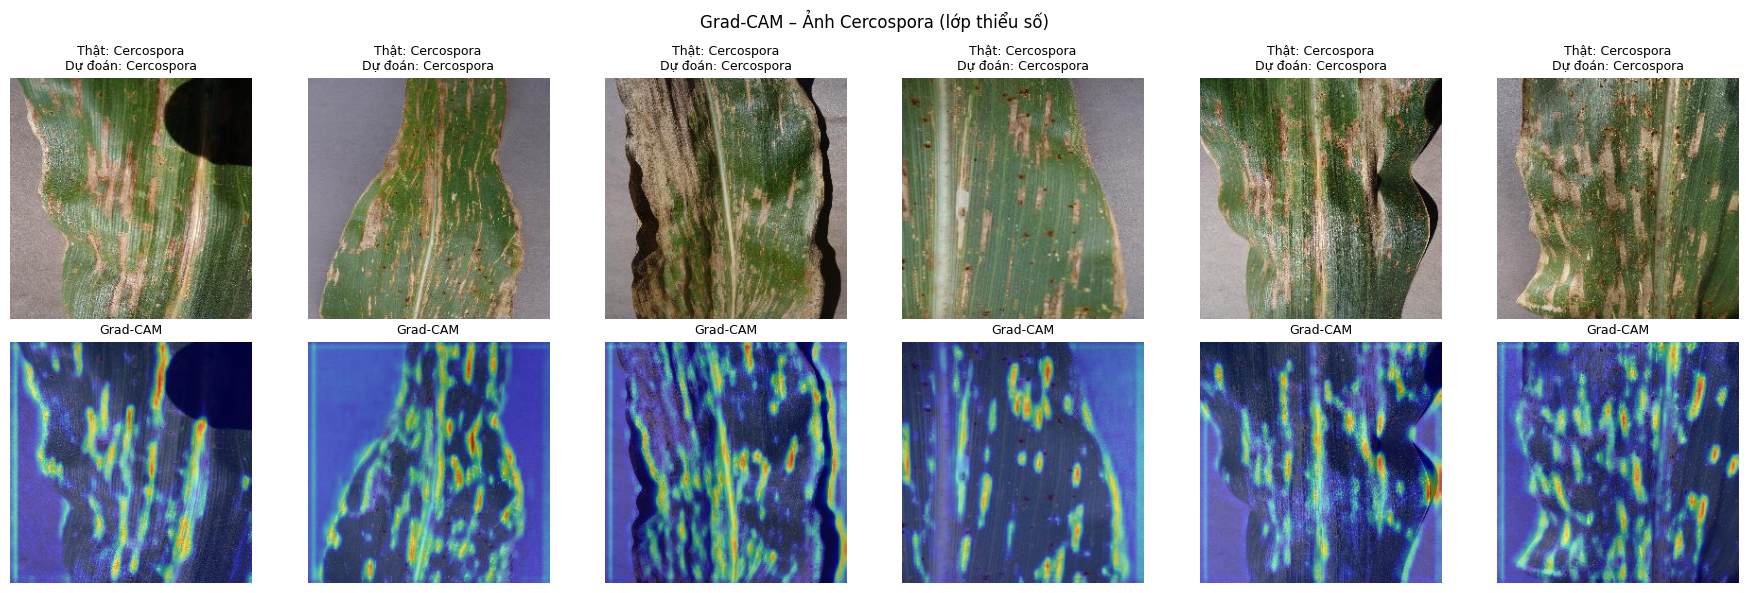

In [8]:
# ---------- GRAD-CAM ----------
import torch.nn.functional as F
import matplotlib.pyplot as plt

def grad_cam(model, img_tensor, target_class=None):
    """
    img_tensor: (1, 3, H, W) đã ở GPU, giá trị [0,1]
    Trả về heatmap (H, W) đã normalize [0,1]
    """
    model.eval()
    features, gradients = [], []

    def fwd_hook(module, inp, out):
        features.append(out)
    def bwd_hook(module, gin, gout):
        gradients.append(gout[0])

    # Lấy lớp conv cuối cùng
    last_conv = None
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            last_conv = m
    handle_f = last_conv.register_forward_hook(fwd_hook)
    handle_b = last_conv.register_full_backward_hook(bwd_hook)

    img_tensor = img_tensor.clone().requires_grad_(True)
    out = model(img_tensor)
    if target_class is None:
        target_class = out.argmax(1).item()
    model.zero_grad()
    out[0, target_class].backward()

    handle_f.remove()
    handle_b.remove()

    feat = features[0][0]          # (C, h, w)
    grad = gradients[0][0]         # (C, h, w)
    weights = grad.mean(dim=(1, 2))  # (C,)
    cam = (weights[:, None, None] * feat).sum(0)
    cam = F.relu(cam)
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)[0, 0]
    return cam.detach().cpu().numpy(), target_class


# Ví dụ: vẽ Grad-CAM cho vài ảnh Cercospora bị nhầm
def show_gradcam_examples(model, n_show=6):
    model.eval()
    # Lấy một số ảnh test thuộc lớp 0 (Cercospora)
    cerc_idx = [i for i in test_idx if y_all[i] == 0][:n_show]
    
    fig, axes = plt.subplots(2, n_show, figsize=(3*n_show, 6))
    for i, idx in enumerate(cerc_idx):
        img = X[idx].float().div(255).unsqueeze(0)  # (1,3,H,W)
        cam, pred = grad_cam(model, img)
        
        # Ảnh gốc
        img_np = X[idx].cpu().permute(1, 2, 0).numpy()
        axes[0, i].imshow(img_np)
        axes[0, i].set_title(f"Thật: Cercospora\nDự đoán: {SHORT[pred]}", fontsize=9)
        axes[0, i].axis("off")
        
        # Heatmap
        axes[1, i].imshow(img_np)
        axes[1, i].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, i].set_title("Grad-CAM", fontsize=9)
        axes[1, i].axis("off")
    
    plt.suptitle("Grad-CAM – Ảnh Cercospora (lớp thiểu số)", fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_DIR / "gradcam_cercospora.png", dpi=150)
    plt.show()

# Chạy với model CNN + BN (seed 45 thường tốt)
set_seed(45)
model_bn = make_cnn(True).to(device)
# Bạn cần load lại weight tốt nhất hoặc huấn luyện nhanh 1 lần
# Ở đây giả sử bạn đã có best_state từ run_one
model_bn.load_state_dict(best_bn_state_45) 
show_gradcam_examples(model_bn)

In [ ]:
## KẾT LUẬN TỔNG KẾT THỰC NGHIỆM

1. **Đặc điểm dữ liệu:** Bộ dữ liệu PlantVillage Maize gồm **3.852 ảnh** thuộc 4 lớp bệnh lý, toàn bộ ảnh đạt chuẩn về chất lượng (không hỏng, không trùng lặp). Dữ liệu có sự mất cân bằng lớp rõ rệt khi lớp thiểu số **Cercospora (Gray Leaf Spot)** chỉ chiếm **13,3%** (513 ảnh), gây khó khăn lớn cho việc phân loại và dễ nhầm lẫn với *Northern Leaf Blight*.
2. **Hiệu quả của Batch Normalization (`CNN + BN` so với `CNN nền`):**
   - Qua thực nghiệm tái lập trên **5 seed độc lập** (42–46), việc bổ sung **Batch Normalization** giúp cải thiện toàn diện hiệu năng: **Test Accuracy** tăng từ **91,94% ± 0,71%** lên **94,60% ± 1,14%**, và **Macro-F1** tăng trung bình **+0,0525** (từ **0,8686** lên **0,9211**).
   - Đặc biệt trên lớp thiểu số *Cercospora*, **F1-score** tăng mạnh từ **0,6219** lên **0,7928** (Recall tăng từ 48,31% lên 73,25%), giảm đáng kể số ca dự đoán nhầm sang *Northern Leaf Blight* (từ 199 ca xuống còn 103 ca trên tổng 5 seed).
3. **Ý nghĩa thống kê & Khả năng giải thích (Grad-CAM):**
   - Khoảng tin cậy **95% Bootstrap CI** của mức chênh lệch Macro-F1 là **[+0,0267 ; +0,0785]** (nằm hoàn toàn trên 0) và kiểm định *t* ghép cặp cho kết quả có ý nghĩa thống kê ($t = 3,314$, $p = 0,0295$, $d_z = 1,48$).
   - Trực quan hóa **Grad-CAM** xác nhận mô hình `CNN + BN` tập trung đúng vào các vùng đốm bệnh đặc trưng trên phiến lá thay vì nhiễu nền.
4. **Danh mục file kết quả đã lưu (`/kaggle/working`):**
   - `class_distribution.png`, `gradcam_cercospora.png` (biểu đồ phân bố lớp và trực quan hóa Grad-CAM).
   - `final_test_results_per_run.csv`, `final_mcnemar_by_seed.csv`, `final_summary.json`, `final_test_predictions.npz` (số liệu đánh giá, kiểm định thống kê và dự đoán chi tiết).